In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_pickle('/home/aleksandr/ssd/Desktop/PhD/p3/git_projects/gcmc-olefins-mof/data/processed/solo_different_T_fixed_50_blocks.pkl')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   blocks_num       132 non-null    int64  
 1   mol_uc_avg       132 non-null    float64
 2   stderr_block     132 non-null    float64
 3   n                132 non-null    int64  
 4   pressure         132 non-null    int64  
 5   temperature      132 non-null    int64  
 6   adsorption_type  132 non-null    object 
 7   file             132 non-null    object 
 8   system           132 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 9.4+ KB


In [3]:
# Calculate the capacity difference (absolute - excess) for each unique file
df_capacity = df.pivot_table(index=['file', 'temperature', 'pressure'], 
                             columns='adsorption_type', 
                             values='mol_uc_avg').reset_index()

# Add a new column for capacity difference
df_capacity['capacity_out'] = df_capacity['absolute'] - df_capacity['excess']

# Display the resulting dataframe
df_capacity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   file          66 non-null     object 
 1   temperature   66 non-null     int64  
 2   pressure      66 non-null     int64  
 3   absolute      66 non-null     float64
 4   excess        66 non-null     float64
 5   capacity_out  66 non-null     float64
dtypes: float64(3), int64(2), object(1)
memory usage: 3.2+ KB


<Axes: xlabel='pressure', ylabel='capacity_out'>

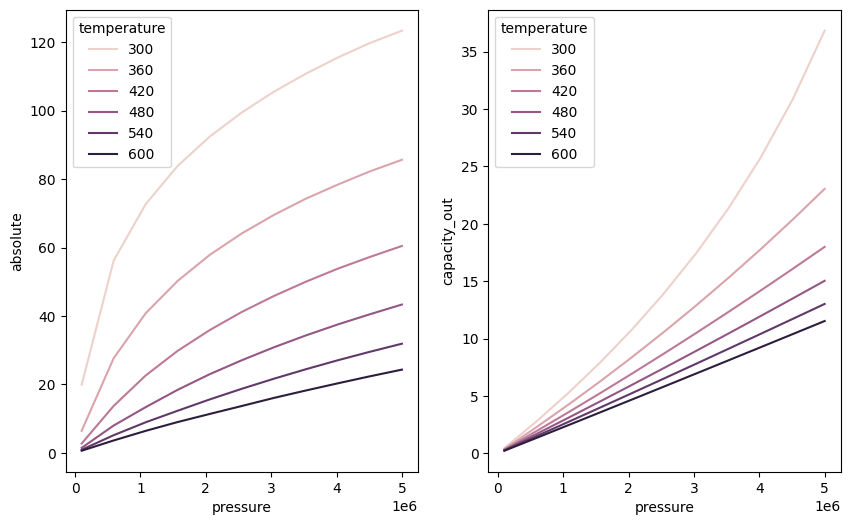

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10, 6))
sns.lineplot(data=df_capacity, x='pressure', y='absolute', hue='temperature', ax=axs[0])
sns.lineplot(data=df_capacity, x='pressure', y='capacity_out', hue='temperature', ax=axs[1])

In [5]:
from kinetic_model.constants.adsorption import (
    PREoS, PerTFitter, PTIsothermPolyModel
)

# 1) Per-T fits (prints/returns the table you already inspected)
eos = PREoS()
perT = PerTFitter(eos, nmax_lb=1.0, b_bounds=(1e-12, 1e-3))
params_df, df_with_fit = perT.fit(df_capacity)

print(params_df)  # parameters at each temperature

# 2) Fit polynomial temperature models (choose log_b=True if log-scale looked linear)
pt_model = PTIsothermPolyModel(eos, degree_nmax=5, degree_b=5, log_b=False)  # or True
pt_model.fit_from_params(params_df)

# (optional) keep your good "out" behavior
pt_model.set_Vp_from_df(df_capacity)  # only if you want out/excess predictions too

# 3) Predict anywhere
df_capacity['pred_absolute_poly'] = pt_model.predict_absolute(df_capacity['pressure'], df_capacity['temperature'])
df_capacity['pred_out_poly'] = pt_model.predict_out(df_capacity['pressure'], df_capacity['temperature'])  # if Vp set
df_capacity['pred_excess_poly'] = df_capacity['pred_absolute_poly'] - df_capacity['pred_out_poly']       # if Vp set


   temperature        nmax             b        KH     f_half_Pa      rmse
0        300.0  158.204223  8.566653e-07  0.000136  1.167317e+06  3.563046
1        360.0  132.666603  4.170130e-07  0.000055  2.398006e+06  1.041830
2        420.0  124.849382  2.059357e-07  0.000026  4.855885e+06  0.264038
3        480.0  125.317226  1.120913e-07  0.000014  8.921299e+06  0.106276
4        540.0  126.331238  6.991204e-08  0.000009  1.430369e+07  0.085300
5        600.0  121.926575  5.068961e-08  0.000006  1.972791e+07  0.077338


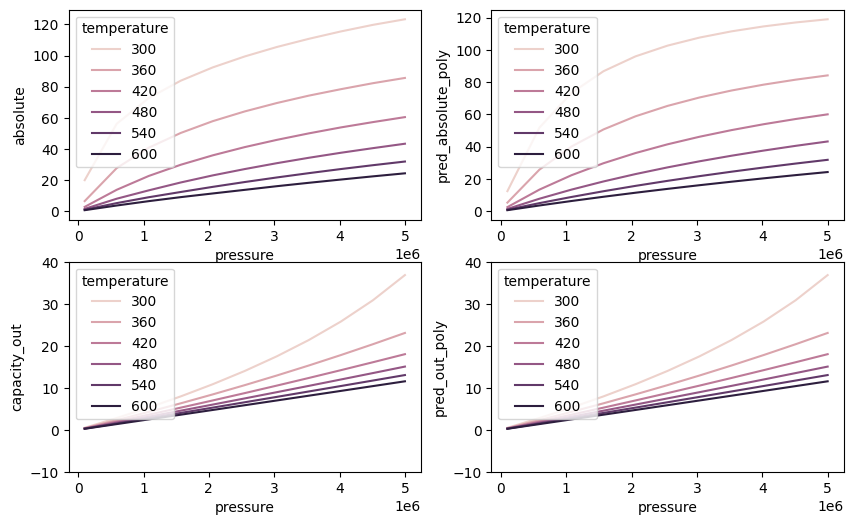

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6))

sns.lineplot(data=df_capacity, x='pressure', y='absolute', hue='temperature', ax=axs[0, 0])
sns.lineplot(data=df_capacity, x='pressure', y='pred_absolute_poly', hue='temperature', ax=axs[0, 1])

sns.lineplot(data=df_capacity, x='pressure', y='capacity_out', hue='temperature', ax=axs[1, 0])
sns.lineplot(data=df_capacity, x='pressure', y='pred_out_poly', hue='temperature', ax=axs[1, 1])

for i in range(2):
    # axs[0, i].set_ylim(-10, 130)
    axs[1, i].set_ylim(-10, 40)

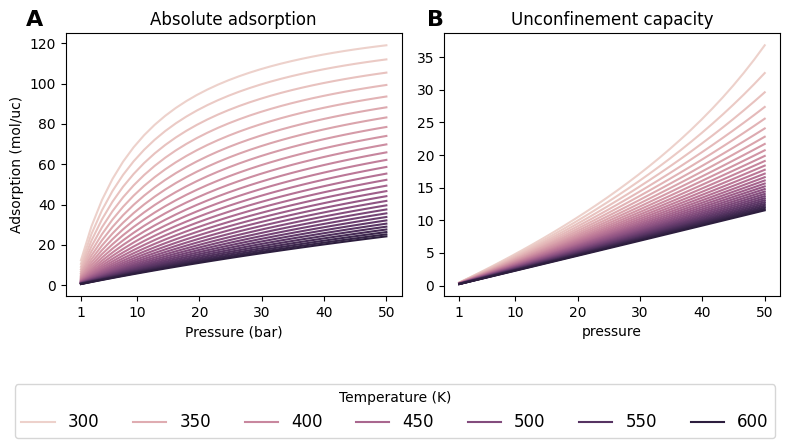

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))


df_test = pd.DataFrame()
for T in np.linspace(300, 600, 30):
    P = np.linspace(1e5, 5e6, 30)
    df_test = pd.concat([df_test, pd.DataFrame({'pressure': P, 'temperature': T})], ignore_index=True)

df_test['pred_absolute_poly'] = pt_model.predict_absolute(df_test['pressure'], df_test['temperature'])
df_test['pred_out_poly'] = pt_model.predict_out(df_test['pressure'], df_test['temperature'])  # if Vp set

sns.lineplot(data=df_test, x='pressure', y='pred_absolute_poly', hue='temperature', ax=axs[0])
sns.lineplot(data=df_test, x='pressure', y='pred_out_poly', hue='temperature', ax=axs[1])

axs[0].set_ylabel('Adsorption (mol/uc)')
axs[1].set_ylabel('')
axs[0].set_xticks([1e5, 1e6, 2e6, 3e6, 4e6, 5e6], labels=['1', '10', '20', '30', '40', '50'])
axs[1].set_xticks([1e5, 1e6, 2e6, 3e6, 4e6, 5e6], labels=['1', '10', '20', '30', '40', '50'])
axs[0].set_xlabel('Pressure (bar)')
axs[0].set_title('Absolute adsorption')
axs[1].set_title('Unconfinement capacity')

handles, labels = axs[0].get_legend_handles_labels()
axs[0].get_legend().remove()
axs[1].get_legend().remove()

fig.text(0.05, 0.94, 'A', ha='center', va='center', fontsize=16, fontweight='bold')
fig.text(0.55, 0.94, 'B', ha='center', va='center', fontsize=16, fontweight='bold')

fig.legend(handles, labels, title='Temperature (K)', loc='upper center', 
           bbox_to_anchor=(0.5, 0.05), ncol=7, fontsize=12)
fig.tight_layout()
plt.subplots_adjust(bottom=0.25)  # Make room for the legend at the bottom
fig.savefig('../experiments/files/plots/C2_adsorption_model.pdf', bbox_inches='tight', dpi=600)

In [8]:
import joblib

file = '../data/adsorption/pt_poly_model.pkl'
if not joblib.os.path.exists(file):
    joblib.dump(pt_model, file)
else:
    print(f"File {file} already exists. Skipping saving the model.")

File ../data/adsorption/pt_poly_model.pkl already exists. Skipping saving the model.
